In [36]:

import pandas as pd
import numpy as np

filename = "/content/breast-cancer-wisconsin.data"

columns = [
    "Sample_Code",
    "Clump_Thickness",
    "Uniformity_Cell_Size",
    "Uniformity_Cell_Shape",
    "Marginal_Adhesion",
    "Single_Epithelial_Cell_Size",
    "Bare_Nuclei",
    "Bland_Chromatin",
    "Normal_Nucleoli",
    "Mitoses",
    "Class"
]

df = pd.read_csv(
    filename,
    header=None,
    names=columns,
    na_values="?"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

print("\nMissing values:")
display(df.isnull().sum())

print("\nClass distribution:")
display(df["Class"].value_counts(dropna=False))


Dataset loaded successfully!
Dataset shape: (699, 11)


,Sample_Code,Clump_Thickness,Uniformity_Cell_Size,Uniformity_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1.0,3,1,1,2
1,1002945,5,4,4,5,7,10.0,3,2,1,2
2,1015425,3,1,1,1,2,2.0,3,1,1,2
3,1016277,6,8,8,1,3,4.0,3,7,1,2
4,1017023,4,1,1,3,2,1.0,3,1,1,2



Missing values:


,0
Sample_Code,0
Clump_Thickness,0
Uniformity_Cell_Size,0
Uniformity_Cell_Shape,0
Marginal_Adhesion,0
Single_Epithelial_Cell_Size,0
Bare_Nuclei,16
Bland_Chromatin,0
Normal_Nucleoli,0
Mitoses,0



Class distribution:


,count
Class,
2,458
4,241


In [37]:

# STEP 2: DATA CLEANING AND PREPROCESSING

# 1. Check dataset dimensions
print("Original dataset shape:", df.shape)

# 2. Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 3. Check missing values
print("\nMissing values before cleaning:")
print(df.isnull().sum())

# 4. Check data types
print("\nData types:")
print(df.dtypes)

# 5. Convert all columns to numeric values
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 6. Remove rows with missing target labels
df = df.dropna(subset=["Class"]).copy()

# 7. Replace missing feature values with column medians
feature_columns = [
    col for col in df.columns
    if col not in ["Sample_Code", "Class"]
]

for col in feature_columns:
    df[col] = df[col].fillna(df[col].median())

# 8. Remove the sample identifier because it is not a predictive feature
df = df.drop(columns=["Sample_Code"])

# 9. Check final dataset
print("\nDataset shape after cleaning:", df.shape)

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nClass distribution after cleaning:")
print(df["Class"].value_counts())

print("\nCleaned dataset preview:")
display(df.head())


Original dataset shape: (699, 11)

Duplicate rows: 8

Missing values before cleaning:
Sample_Code                     0
Clump_Thickness                 0
Uniformity_Cell_Size            0
Uniformity_Cell_Shape           0
Marginal_Adhesion               0
Single_Epithelial_Cell_Size     0
Bare_Nuclei                    16
Bland_Chromatin                 0
Normal_Nucleoli                 0
Mitoses                         0
Class                           0
dtype: int64

Data types:
Sample_Code                      int64
Clump_Thickness                  int64
Uniformity_Cell_Size             int64
Uniformity_Cell_Shape            int64
Marginal_Adhesion                int64
Single_Epithelial_Cell_Size      int64
Bare_Nuclei                    float64
Bland_Chromatin                  int64
Normal_Nucleoli                  int64
Mitoses                          int64
Class                            int64
dtype: object

Dataset shape after cleaning: (699, 10)

Missing values after cleaning

,Clump_Thickness,Uniformity_Cell_Size,Uniformity_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Class
0,5,1,1,1,2,1.0,3,1,1,2
1,5,4,4,5,7,10.0,3,2,1,2
2,3,1,1,1,2,2.0,3,1,1,2
3,6,8,8,1,3,4.0,3,7,1,2
4,4,1,1,3,2,1.0,3,1,1,2


Dataset shape: (699, 11)

Diagnosis distribution:
Diagnosis
Benign       458
Malignant    241
Name: count, dtype: int64


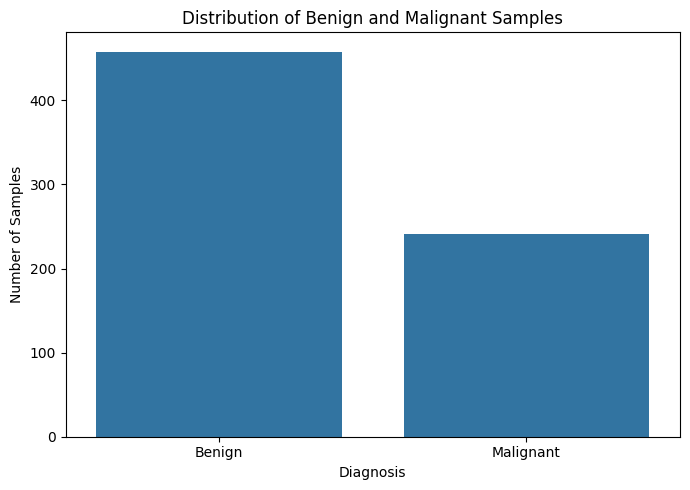


Summary Statistics:


,Clump_Thickness,Uniformity_Cell_Size,Uniformity_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses
count,699.000000,699.000000,699.000000,699.000000,699.000000,699.000000,699.000000,699.000000,699.000000
mean,4.417740,3.134478,3.207439,2.806867,3.216023,3.486409,3.437768,2.866953,1.589413
std,2.815741,3.051459,2.971913,2.855379,2.214300,3.621929,2.438364,3.053634,1.715078
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,2.000000,1.000000,1.000000,1.000000,2.000000,1.000000,2.000000,1.000000,1.000000
50%,4.000000,1.000000,1.000000,1.000000,2.000000,1.000000,3.000000,1.000000,1.000000
75%,6.000000,5.000000,5.000000,4.000000,4.000000,5.000000,5.000000,4.000000,1.000000
max,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000


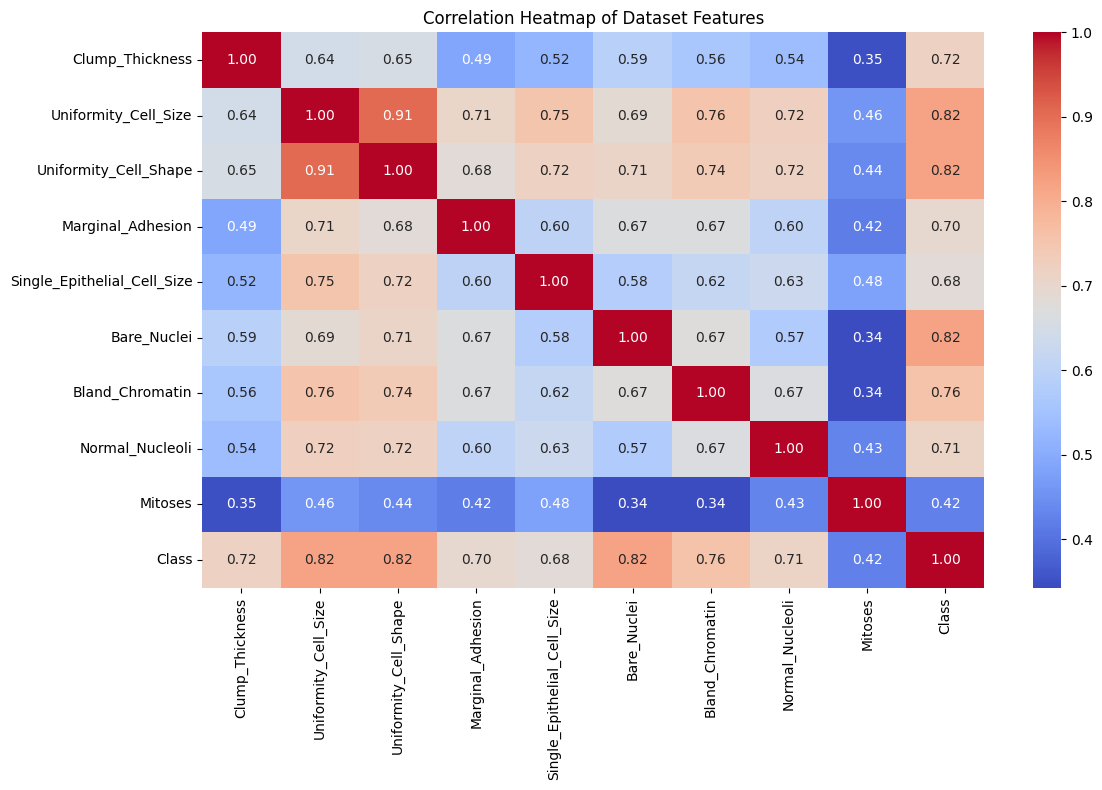

In [38]:

# STEP 3: EXPLORATORY DATA ANALYSIS (EDA)

import matplotlib.pyplot as plt
import seaborn as sns

# Convert original class labels into readable names
df["Diagnosis"] = df["Class"].map({
    2: "Benign",
    4: "Malignant"
})

print("Dataset shape:", df.shape)

print("\nDiagnosis distribution:")
print(df["Diagnosis"].value_counts())

# Visualize the target class distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Diagnosis")
plt.title("Distribution of Benign and Malignant Samples")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

# Summary statistics of the numerical features
print("\nSummary Statistics:")
display(df.drop(columns=["Class", "Diagnosis"]).describe())

# Feature correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    df.drop(columns=["Diagnosis"]).corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)
plt.title("Correlation Heatmap of Dataset Features")
plt.tight_layout()
plt.show()


In [39]:

# STEP 4: FEATURE SELECTION AND TRAIN-TEST SPLIT

from sklearn.model_selection import train_test_split

# Select input features and target
X = df.drop(columns=["Class", "Diagnosis"])
y = df["Class"].map({
    2: 0,   # Benign
    4: 1    # Malignant
})

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nTarget mapping:")
print("0 = Benign")
print("1 = Malignant")

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())


Feature matrix shape: (699, 9)
Target vector shape: (699,)

Target mapping:
0 = Benign
1 = Malignant

Training samples: 559
Testing samples: 140

Training class distribution:
Class
0    366
1    193
Name: count, dtype: int64

Testing class distribution:
Class
0    92
1    48
Name: count, dtype: int64


In [40]:

# STEP 5: FEATURE SCALING, MODEL TRAINING AND CROSS-VALIDATION

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Create a pipeline to prevent data leakage
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42))
])

# 5-fold stratified cross-validation on training data only
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("5-Fold Cross-Validation Results")
print("--------------------------------")

for i, score in enumerate(cv_scores, start=1):
    print(f"Fold {i} Accuracy: {score:.4f}")

print(f"\nMean CV Accuracy: {cv_scores.mean():.4f}")
print(f"Standard Deviation: {cv_scores.std():.4f}")

# Train the final model on the full training set
model.fit(X_train, y_train)

print("\nModel training completed successfully!")


5-Fold Cross-Validation Results
--------------------------------
Fold 1 Accuracy: 0.9732
Fold 2 Accuracy: 0.9643
Fold 3 Accuracy: 0.9375
Fold 4 Accuracy: 0.9732
Fold 5 Accuracy: 0.9910

Mean CV Accuracy: 0.9678
Standard Deviation: 0.0175

Model training completed successfully!


In [41]:

# STEP 6: MODEL EVALUATION

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Predict on unseen test data
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
results = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-Score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}

print("Test Set Evaluation Results")
print("---------------------------")

for metric, value in results.items():
    print(f"{metric}: {value:.4f}")

print("\nDetailed Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Benign", "Malignant"],
    zero_division=0
))


Test Set Evaluation Results
---------------------------
Accuracy: 0.9500
Precision: 0.9362
Recall: 0.9167
F1-Score: 0.9263
ROC-AUC: 0.9950

Detailed Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      0.97      0.96        92
   Malignant       0.94      0.92      0.93        48

    accuracy                           0.95       140
   macro avg       0.95      0.94      0.94       140
weighted avg       0.95      0.95      0.95       140



Confusion Matrix:
[[89  3]
 [ 4 44]]


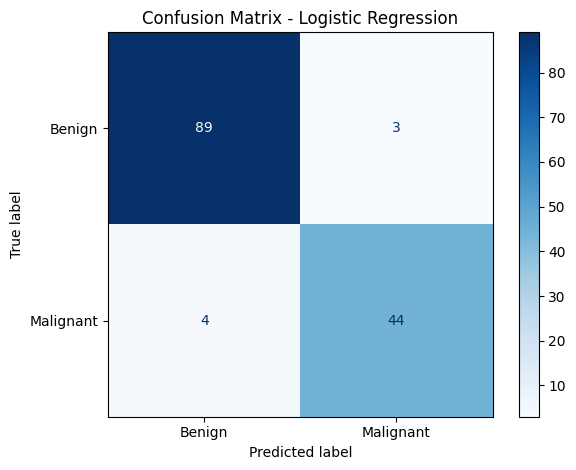

In [42]:

# STEP 7A: CONFUSION MATRIX

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()


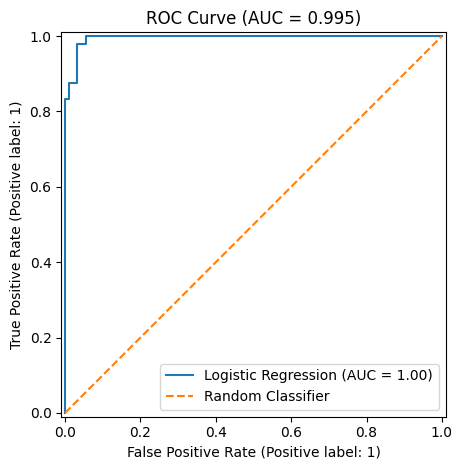

Test ROC-AUC Score: 0.9950


In [43]:

# STEP 7B: ROC CURVE

from sklearn.metrics import RocCurveDisplay, roc_auc_score

auc_score = roc_auc_score(y_test, y_prob)

RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name="Logistic Regression"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.title(f"ROC Curve (AUC = {auc_score:.3f})")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Test ROC-AUC Score: {auc_score:.4f}")


Feature correlations with target:


,Correlation_with_Target
Bare_Nuclei,0.831074
Uniformity_Cell_Shape,0.814591
Uniformity_Cell_Size,0.814098
Bland_Chromatin,0.748385
Normal_Nucleoli,0.722584
Clump_Thickness,0.719433
Marginal_Adhesion,0.700828
Single_Epithelial_Cell_Size,0.677692
Mitoses,0.439536


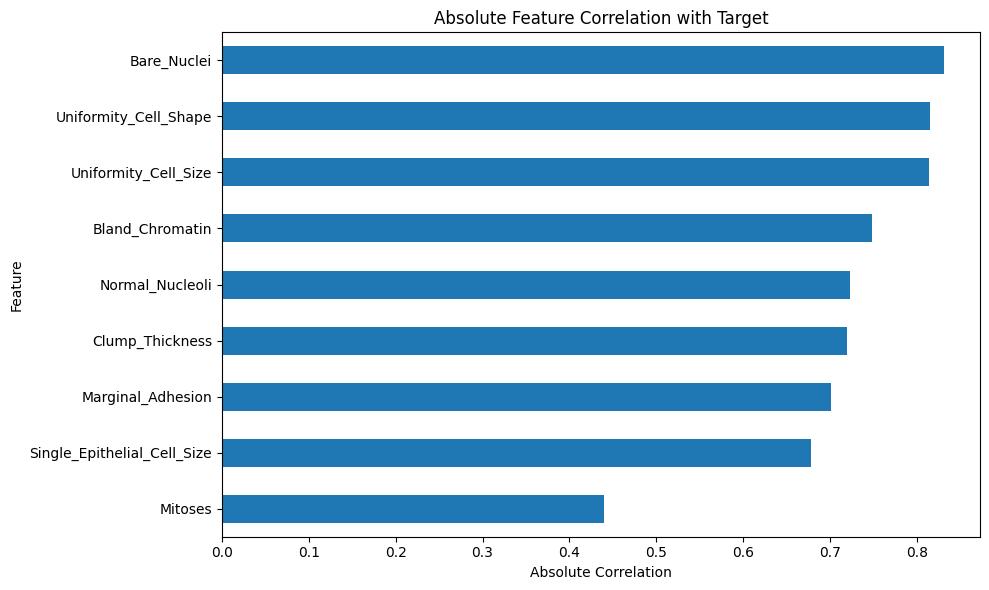

In [44]:

# STEP 7C: FEATURE ANALYSIS

# Calculate correlation with the binary target
feature_correlations = (
    X_train.assign(Target=y_train)
    .corr(numeric_only=True)["Target"]
    .drop("Target")
    .sort_values(key=abs, ascending=False)
)

print("Feature correlations with target:")
display(feature_correlations.to_frame("Correlation_with_Target"))

# Visualize the absolute correlation values
plt.figure(figsize=(10, 6))

feature_correlations.abs().sort_values().plot(
    kind="barh"
)

plt.title("Absolute Feature Correlation with Target")
plt.xlabel("Absolute Correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [45]:

# STEP 8: MODEL PERFORMANCE SUMMARY

print("PROJECT: BREAST CANCER CLASSIFICATION")
print("=" * 45)

print("\n1. CROSS-VALIDATION")
print(f"Mean CV Accuracy: {cv_scores.mean():.4f}")
print(f"CV Standard Deviation: {cv_scores.std():.4f}")

print("\n2. TEST SET PERFORMANCE")
for metric, value in results.items():
    print(f"{metric}: {value:.4f}")

print("\n3. MODEL STRENGTHS")
print("- Logistic Regression is simple and interpretable.")
print("- StandardScaler is included in the pipeline.")
print("- Stratified cross-validation evaluates consistency.")
print("- Multiple metrics provide a broader evaluation.")

print("\n4. MODEL LIMITATIONS")
print("- Logistic Regression may not capture complex nonlinear patterns.")
print("- Performance depends on the dataset and selected features.")
print("- The dataset may not represent all real-world patients.")
print("- This model is for educational purposes, not medical diagnosis.")

print("\n5. POSSIBLE IMPROVEMENTS")
print("- Compare Logistic Regression with Random Forest and SVM.")
print("- Use hyperparameter tuning.")
print("- Analyse false negatives carefully.")
print("- Evaluate performance on an independent external dataset.")


PROJECT: BREAST CANCER CLASSIFICATION

1. CROSS-VALIDATION
Mean CV Accuracy: 0.9678
CV Standard Deviation: 0.0175

2. TEST SET PERFORMANCE
Accuracy: 0.9500
Precision: 0.9362
Recall: 0.9167
F1-Score: 0.9263
ROC-AUC: 0.9950

3. MODEL STRENGTHS
- Logistic Regression is simple and interpretable.
- StandardScaler is included in the pipeline.
- Stratified cross-validation evaluates consistency.
- Multiple metrics provide a broader evaluation.

4. MODEL LIMITATIONS
- Logistic Regression may not capture complex nonlinear patterns.
- Performance depends on the dataset and selected features.
- The dataset may not represent all real-world patients.
- This model is for educational purposes, not medical diagnosis.

5. POSSIBLE IMPROVEMENTS
- Compare Logistic Regression with Random Forest and SVM.
- Use hyperparameter tuning.
- Analyse false negatives carefully.
- Evaluate performance on an independent external dataset.


In [46]:

# STEP 9: SAVE EVALUATION RESULTS

evaluation_df = pd.DataFrame(
    list(results.items()),
    columns=["Evaluation_Metric", "Score"]
)

display(evaluation_df)

evaluation_df.to_csv(
    "Week_4_Evaluation_Results.csv",
    index=False
)

print("Evaluation results saved successfully.")


,Evaluation_Metric,Score
0,Accuracy,0.950000
1,Precision,0.936170
2,Recall,0.916667
3,F1-Score,0.926316
4,ROC-AUC,0.995018


Evaluation results saved successfully.


In [47]:

# STEP 9: FINAL MODEL RESULTS

print("WEEK 4: SUPERVISED LEARNING RESULTS")
print("=" * 45)

print("\nCross-Validation")
print(f"Mean Accuracy: {cv_scores.mean():.4f}")
print(f"Standard Deviation: {cv_scores.std():.4f}")

print("\nTest Set Metrics")
for metric, score in results.items():
    print(f"{metric}: {score:.4f}")

print("\nClassification Report")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Benign", "Malignant"],
    zero_division=0
))


WEEK 4: SUPERVISED LEARNING RESULTS

Cross-Validation
Mean Accuracy: 0.9678
Standard Deviation: 0.0175

Test Set Metrics
Accuracy: 0.9500
Precision: 0.9362
Recall: 0.9167
F1-Score: 0.9263
ROC-AUC: 0.9950

Classification Report
              precision    recall  f1-score   support

      Benign       0.96      0.97      0.96        92
   Malignant       0.94      0.92      0.93        48

    accuracy                           0.95       140
   macro avg       0.95      0.94      0.94       140
weighted avg       0.95      0.95      0.95       140



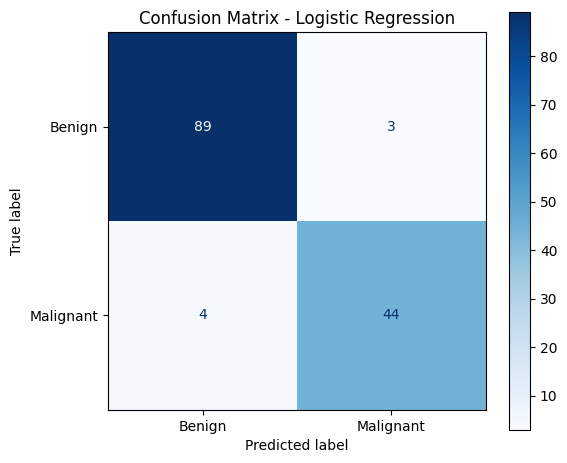

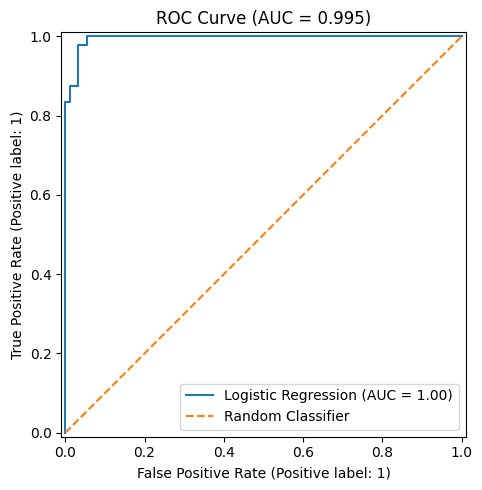

Evaluation table and graphs saved successfully!


In [48]:

# STEP 10: SAVE GRAPHS AND RESULT TABLES

import os

os.makedirs("Week_4_Results", exist_ok=True)

# Save evaluation metrics
evaluation_df = pd.DataFrame(
    list(results.items()),
    columns=["Metric", "Score"]
)

evaluation_df.to_csv(
    "Week_4_Results/Evaluation_Metrics.csv",
    index=False
)

# Save confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
).plot(ax=ax, cmap="Blues", values_format="d")

ax.set_title("Confusion Matrix - Logistic Regression")
fig.tight_layout()
fig.savefig(
    "Week_4_Results/Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# Save ROC curve
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name="Logistic Regression",
    ax=ax
)
ax.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
ax.set_title(f"ROC Curve (AUC = {auc_score:.3f})")
ax.legend()
fig.tight_layout()
fig.savefig(
    "Week_4_Results/ROC_Curve.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# Save cross-validation scores
pd.DataFrame({
    "Fold": range(1, len(cv_scores) + 1),
    "Accuracy": cv_scores
}).to_csv(
    "Week_4_Results/Cross_Validation_Scores.csv",
    index=False
)

print("Evaluation table and graphs saved successfully!")


In [49]:

# STEP 11: CHECK NOTEBOOK FILE NAME

import os

print("Files available in Colab:")
print(os.listdir("/content"))


Files available in Colab:
['.config', 'Week_4_Evaluation_Results.csv', 'Week_4_Results', 'breast-cancer-wisconsin.data', 'Week_4_Results.zip', 'sample_data']


In [50]:

# STEP 12: DOWNLOAD ALL RESULT FILES AS ZIP

import shutil
from google.colab import files

shutil.make_archive(
    "Week_4_Results",
    "zip",
    "Week_4_Results"
)

files.download("Week_4_Results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

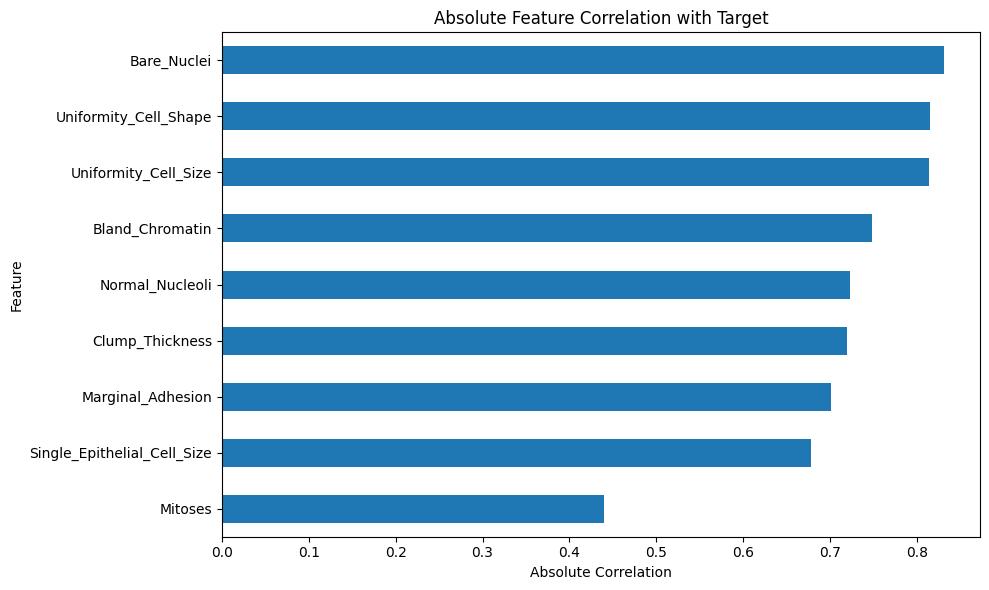

Feature correlation graph saved!


In [51]:

# Save feature correlation graph
import os

os.makedirs("Week_4_Results", exist_ok=True)

fig, ax = plt.subplots(figsize=(10, 6))

feature_correlations.abs().sort_values().plot(
    kind="barh",
    ax=ax
)

ax.set_title("Absolute Feature Correlation with Target")
ax.set_xlabel("Absolute Correlation")
ax.set_ylabel("Feature")

fig.tight_layout()
fig.savefig(
    "Week_4_Results/Feature_Correlation.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Feature correlation graph saved!")


In [52]:

# STEP 13: SAMPLE PREDICTION CHECK

sample_data = X_test.iloc[:5]
actual = y_test.iloc[:5]
predicted = model.predict(sample_data)

comparison = pd.DataFrame({
    "Actual_Class": actual.map({
        0: "Benign",
        1: "Malignant"
    }),
    "Predicted_Class": pd.Series(
        predicted,
        index=actual.index
    ).map({
        0: "Benign",
        1: "Malignant"
    })
})

comparison["Correct_Prediction"] = (
    comparison["Actual_Class"]
    == comparison["Predicted_Class"]
)

display(comparison)


,Actual_Class,Predicted_Class,Correct_Prediction
549,Malignant,Malignant,True
154,Benign,Benign,True
297,Benign,Benign,True
96,Benign,Benign,True
493,Malignant,Malignant,True


In [53]:

import os

print("PROJECT FILE CHECK")
print("=" * 35)

paths = [
    "/content/Week_4_Results",
    "/content/Week_4_Evaluation_Results.csv",
    "/content/Week_4_Results.zip",
    "/content/breast-cancer-wisconsin.data"
]

for path in paths:
    print(
        os.path.basename(path),
        "->",
        "Available" if os.path.exists(path) else "Not found"
    )


PROJECT FILE CHECK
Week_4_Results -> Available
Week_4_Evaluation_Results.csv -> Available
Week_4_Results.zip -> Available
breast-cancer-wisconsin.data -> Available
